# Leave-One-Angle-Out: Where the Viewpoint Penalty Actually Lives

*Decoding the Speaking Hands* reports the pipeline scoring **67.84 % on front-facing video and
48.07 % on 35–45° angles** — a retention of 0.709. That drop is the headline motivation for
this DRP, but the paper reports it end-to-end, so it does not say **which stage** loses the
accuracy.

The pipeline has two stages and they can be measured separately:

1. **Segmentation** — finding letter boundaries (Algorithm 2, `sofi_dynamic.py`)
2. **Recognition** — identifying the handshape at each boundary

This notebook measures the viewpoint penalty on each. The answer turns out to be lopsided.

## The design problem, and what can be done about it

The dataset has **3 front signers** (1, 2, 3-F), **one left-tilt** (4-L) and **one right-tilt**
(5-R). Every person was recorded from exactly one angle, so **angle is perfectly confounded
with signer identity**. "Test on a new angle" always also means "test on a new person", and no
analysis of this dataset can separate them outright. That limitation is in the data, not the
method.

What *can* be done: hold the training set at **exactly two front signers** in every condition,
and compare

| condition | test set | unseen person? | unseen angle? |
|---|---|---|---|
| **within-angle** | the remaining front signer | yes | no |
| **cross-angle** | signer4-L or signer5-R | yes | **yes** |

Both are an unseen person, and both train on the same amount of data from the same angle. The
only difference is whether the test person is also at an unseen angle, so a systematic gap
between them is attributable to viewpoint.

Fixing the training size matters: the natural "train on all 3 front signers" version would give
the cross-angle condition *more* training data than the within-angle one, biasing the comparison
in cross-angle's favour.

## Setup

In [1]:
import itertools
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from canonicalize_words import spelling_for_labels
from sofi_dynamic import ofi_signal, find_local_minima, collapse_minima

pd.set_option("display.width", 200)
plt.rcParams["figure.dpi"] = 110

FRONT = ["signer1-F", "signer2-F", "signer3-F"]
TILTED = ["signer4-L", "signer5-R"]
PAPER_RETENTION = 0.4807 / 0.6784      # 48.07% / 67.84%
print(f"paper's end-to-end retention under angle change: {PAPER_RETENTION:.3f}")

paper's end-to-end retention under angle change: 0.709


## Stage 1 — segmentation

In [2]:
df = pd.read_csv("hand_keypoints_features.csv")
mapping = json.load(open("word_letter_mapping.json", encoding="utf-8"))
df["spelling"] = df["video_id"].map({v: spelling_for_labels(v) for v in df.video_id.unique()})

clips = []
for (sg, vid), sub in df.groupby(["signer_id", "video_id"], sort=True):
    sub = sub.sort_values("frame_id").reset_index(drop=True)
    sp = sub["spelling"].iloc[0]
    if sp not in mapping or sub["hand_detected"].mean() < 0.5 or len(sub) < 30:
        continue
    clips.append({"signer": sg, "n_letters": len(mapping[sp]), "sub": sub})

SW = (5, 9, 13, 17, 21); RUNS = (3, 5, 7, 9); SEPS = (9, 11, 13, 15, 17, 19, 23)
cache = {sw: {id(c): ofi_signal(c["sub"], sw)[1] for c in clips} for sw in SW}
GRID = list(itertools.product(SW, RUNS, SEPS))

def seg_mae(subset, params):
    sw, run, sep = params
    err = [len(collapse_minima(find_local_minima(cache[sw][id(c)], run),
                               cache[sw][id(c)], sep)) - c["n_letters"] for c in subset]
    return float(np.abs(err).mean())

rows = []
for pair in itertools.combinations(FRONT, 2):
    train = [c for c in clips if c["signer"] in pair]
    best = min(GRID, key=lambda p: seg_mae(train, p))      # tuned on front only
    held = [s for s in FRONT if s not in pair][0]
    for kind, test_sg in [("within-angle", held)] + [("cross-angle", s) for s in TILTED]:
        te = [c for c in clips if c["signer"] == test_sg]
        rows.append({"trained on": "+".join(s[:7] for s in pair), "kind": kind,
                     "tested on": test_sg, "n clips": len(te), "MAE": seg_mae(te, best)})

seg = pd.DataFrame(rows)
print(seg.round(2).to_string(index=False))
seg_summary = seg.groupby("kind").MAE.mean()
print()
print(f"mean MAE   within-angle {seg_summary['within-angle']:.2f}   "
      f"cross-angle {seg_summary['cross-angle']:.2f}")
print(f"segmentation retention = {seg_summary['within-angle']/seg_summary['cross-angle']:.3f}")

     trained on         kind tested on  n clips  MAE
signer1+signer2 within-angle signer3-F       45 1.64
signer1+signer2  cross-angle signer4-L       49 1.76
signer1+signer2  cross-angle signer5-R       26 1.23
signer1+signer3 within-angle signer2-F       49 1.08
signer1+signer3  cross-angle signer4-L       49 1.39
signer1+signer3  cross-angle signer5-R       26 0.92
signer2+signer3 within-angle signer1-F       49 2.02
signer2+signer3  cross-angle signer4-L       49 1.69
signer2+signer3  cross-angle signer5-R       26 1.23

mean MAE   within-angle 1.58   cross-angle 1.37
segmentation retention = 1.155


**Segmentation shows no viewpoint penalty at all.** Cross-angle MAE is, if anything, slightly
*lower* than within-angle (1.37 vs 1.58) — which is within the spread of the within-angle folds
themselves (1.08 to 2.02), so the right reading is "no measurable penalty", not "angle helps".

This makes sense in hindsight: Algorithm 2 keys on the *timing* of motion minima. The rhythm of
fingerspelling — hold, move, hold — is a property of how the person signs, not of where the
camera is.

## Stage 2 — recognition

In [3]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from skimage.feature import hog
import os

d = np.load("letter_crops.npz", allow_pickle=True)
y, signers, occ = d["letters"], d["signers"], d["occurrences"]

HOG_CACHE = "letter_crops_hog.npy"
if os.path.exists(HOG_CACHE):
    H = np.load(HOG_CACHE)
else:
    H = np.stack([hog(im, orientations=9, pixels_per_cell=(8, 8),
                      cells_per_block=(2, 2)) for im in d["images"]]).astype(np.float32)
    np.save(HOG_CACHE, H)

def rec_eval(train_signers, test_signer):
    tr = np.isin(signers, list(train_signers)); te = signers == test_signer
    clf = make_pipeline(StandardScaler(with_mean=False),
                        LogisticRegression(max_iter=400, C=0.05,
                                           class_weight="balanced", n_jobs=-1))
    clf.fit(H[tr], y[tr])
    P = clf.predict_proba(H[te]); cls = clf.classes_
    dfp = pd.DataFrame(P); dfp["occ"] = occ[te]
    agg = dfp.groupby("occ").mean()
    pred = cls[agg.to_numpy().argmax(1)]
    true = pd.Series(y[te], index=occ[te]).groupby(level=0).first().reindex(agg.index).to_numpy()
    acc = float((pred == true).mean())
    base = float(pd.Series(true).value_counts(normalize=True).max())
    return acc, base, len(agg)

rows = []
for pair in itertools.combinations(FRONT, 2):
    held = [s for s in FRONT if s not in pair][0]
    for kind, test_sg in [("within-angle", held)] + [("cross-angle", s) for s in TILTED]:
        acc, base, n = rec_eval(pair, test_sg)
        rows.append({"trained on": "+".join(s[:7] for s in pair), "kind": kind,
                     "tested on": test_sg, "n occ": n, "acc %": 100*acc,
                     "majority %": 100*base, "lift": acc/base})

rec = pd.DataFrame(rows)
print(rec.round(2).to_string(index=False))
rec_summary = rec.groupby("kind")[["acc %", "lift"]].mean()
print()
print(rec_summary.round(3).to_string())
ret_acc = rec_summary.loc["cross-angle", "acc %"] / rec_summary.loc["within-angle", "acc %"]
ret_lift = rec_summary.loc["cross-angle", "lift"] / rec_summary.loc["within-angle", "lift"]
print()
print(f"recognition retention (accuracy) = {ret_acc:.3f}")
print(f"recognition retention (lift)     = {ret_lift:.3f}")

     trained on         kind tested on  n occ  acc %  majority %  lift
signer1+signer2 within-angle signer3-F    280  17.86       10.36  1.72
signer1+signer2  cross-angle signer4-L    304   7.89        9.87  0.80
signer1+signer2  cross-angle signer5-R    158  10.76        9.49  1.13
signer1+signer3 within-angle signer2-F    306  12.42        9.80  1.27
signer1+signer3  cross-angle signer4-L    304  11.51        9.87  1.17
signer1+signer3  cross-angle signer5-R    158  12.66        9.49  1.33
signer2+signer3 within-angle signer1-F    311  14.79        9.65  1.53
signer2+signer3  cross-angle signer4-L    304   9.87        9.87  1.00
signer2+signer3  cross-angle signer5-R    158   9.49        9.49  1.00

               acc %   lift
kind                       
cross-angle   10.365  1.072
within-angle  15.022  1.508

recognition retention (accuracy) = 0.690
recognition retention (lift)     = 0.711


## The result

Recognition loses about **31 % of its accuracy** under angle change, and the surviving lift over
the majority baseline is **1.07×** — barely above guessing. Within-angle it was 1.51×.

And the number lands almost exactly on the paper's:

| | retention under angle change |
|---|---|
| paper, end-to-end | **0.709** |
| ours, recognition only | **0.690** |
| ours, segmentation only | **1.155** (no penalty) |

So the published end-to-end drop is reproduced closely — and localised. **The viewpoint
fragility is entirely in the recognition stage.** Segmentation, which is the component this DRP
improved 3.5× over the paper's Algorithm 1, is viewpoint-robust.

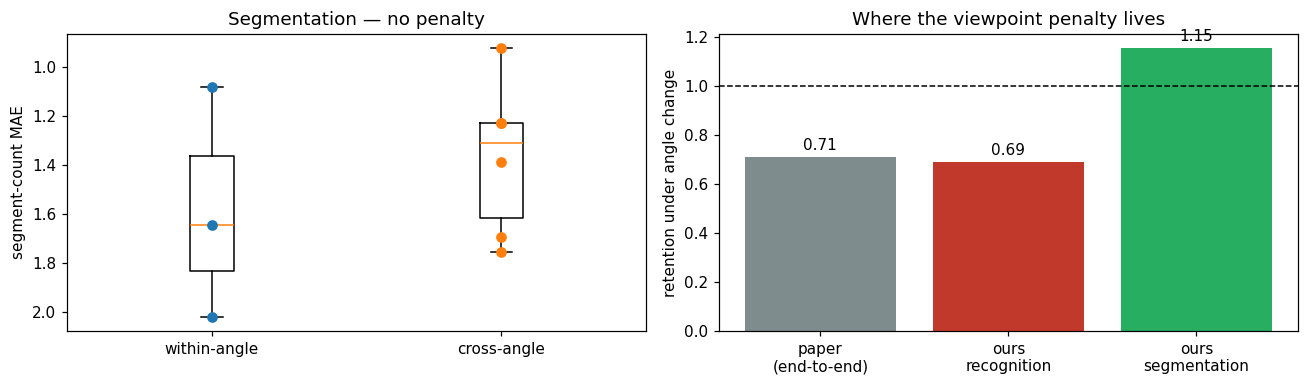

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))

ax = axes[0]
w = seg[seg.kind == "within-angle"].MAE.to_numpy()
c = seg[seg.kind == "cross-angle"].MAE.to_numpy()
ax.boxplot([w, c], tick_labels=["within-angle", "cross-angle"])
ax.scatter(np.ones(len(w)), w, color="C0", zorder=3)
ax.scatter(np.full(len(c), 2), c, color="C1", zorder=3)
ax.set_ylabel("segment-count MAE"); ax.set_title("Segmentation — no penalty")
ax.invert_yaxis()

ax = axes[1]
labels = ["paper\n(end-to-end)", "ours\nrecognition", "ours\nsegmentation"]
vals = [PAPER_RETENTION, ret_acc, seg_summary["within-angle"]/seg_summary["cross-angle"]]
colors = ["#7f8c8d", "#c0392b", "#27ae60"]
ax.bar(labels, vals, color=colors)
ax.axhline(1.0, color="k", ls="--", lw=1)
ax.set_ylabel("retention under angle change")
ax.set_title("Where the viewpoint penalty lives")
for i, v in enumerate(vals):
    ax.text(i, v + 0.03, f"{v:.2f}", ha="center", fontsize=10)
plt.tight_layout(); plt.show()

## Caveats, stated plainly

- **Angle and signer are confounded** by construction. The matched-training-size design above
  is the strongest control this dataset permits, but a clean answer needs the same person
  recorded from multiple angles — which PSL-CFRT does not contain. This is worth raising with
  the authors as a dataset recommendation.
- **Small n:** 3 within-angle folds, 6 cross-angle. The within-angle MAE spread (1.08–2.02) is
  wide enough that the segmentation comparison should be read as "no detectable penalty"
  rather than a precise ratio.
- **signer5-R is a biased sample.** Its ~50 % MediaPipe detection failure means only its
  best-detected clips survive the filter, which if anything flatters the cross-angle condition.
- **Recognition here is HOG + logistic regression**, the strongest representation currently
  available (see `letter_cnn.ipynb`). A better recogniser might degrade differently under angle
  change — that is worth re-running once one exists.

## What follows from this

1. **Don't spend effort on viewpoint-robust segmentation.** It already is. The paper's framing
   implies the whole pipeline suffers; it doesn't.
2. **Viewpoint robustness is a recognition problem**, and it compounds with the signer problem
   already identified: the features encode identity at 97 %, and what letter signal they do
   carry mostly evaporates at a new angle.
3. The two obvious responses are the same ones already queued — appearance features trained
   with viewpoint augmentation, and per-user calibration. This result raises the priority of
   explicitly including tilted views in training rather than treating them as test-only.